In [1]:
# Imports
import math
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
from scipy import stats
import seaborn as sns


In [ ]:
#Getting the Average success values from the Rag and No Rag runs
df = pd.read_csv('oneshot/vitis_oneshot1.csv')
df2 = pd.read_csv('oneshot/vitis_oneshot2.csv')

# Formatting the successes and model names
df['latency'] = pd.to_numeric(df['latency'], errors='coerce')
df['model'] = df['model'].str.split('/').str[-1]
df2['latency'] = pd.to_numeric(df2['latency'], errors='coerce')
df2['model'] = df2['model'].str.split('/').str[-1]


#Getting success Rates
success_cnts_unsort = df.groupby(['model', 'RAG'])['csim_success'].sum()
success_counts = df.groupby(['model', 'RAG'])['csim_success'].sum().sort_values(ascending=False)
total_tests = 101
success1 = (success_counts / total_tests) * 100
success1_unsort = (success_cnts_unsort / total_tests) * 100

success_cnts_unsort = df2.groupby(['model', 'RAG'])['csim_success'].sum()
success_counts = df2.groupby(['model', 'RAG'])['csim_success'].sum().sort_values(ascending=False)
total_tests = 101
success2 = (success_counts / total_tests) * 100
success2_unsort = (success_cnts_unsort / total_tests) * 100

average_success = (success1 + success2) /2
average_success_unsort = (success1_unsort + success2_unsort) /2

average_success = average_success.reset_index(name='csim_success')

#Averaging the success rates
# print(average_success_unsort)
# print(avg_success_norag)

#Get Average Price per Call in each Rag v NoRag run
model_costs_data_norag = {
    'model': ['gemini-2.5-flash', 'deepseek-chat-v3-0324', 'deepseek-r1-0528', 'gpt-4.1-mini', 'grok-code-fast-1',  
              'qwen3-coder', 'gpt-5', 'grok-4', 'gemini-2.5-pro', 'claude-sonnet-4.5'],
    'Base_Cost_Per_Run': [0.25, 0.08, 0.88, 0.12, 0.15, 0.08, 2.66, 6.07, 4.48, 1.92],
    'Cost_STD': [0.16, 0.05, 0.46, 0.06, 0.06, 0.07, 1.05, 4.12, 2.61, 1.16]
}
costs_norag = pd.DataFrame(model_costs_data_norag).set_index('model')

model_costs_data_rag = {
    'model': ['gemini-2.5-flash', 'deepseek-chat-v3-0324', 'deepseek-r1-0528', 'gpt-4.1-mini', 'grok-code-fast-1',  
              'qwen3-coder', 'gpt-5', 'grok-4', 'gemini-2.5-pro', 'claude-sonnet-4.5'],
    'Base_Cost_Per_Run': [0.22, 0.12, 0.92, 0.17, 0.18, 0.09, 2.93, 7.90, 6.13, 1.92]
}
costs_rag = pd.DataFrame(model_costs_data_rag).set_index('model')


# costs_rag.rename(columns={'Model': 'model'}, inplace=True)
# costs_norag.rename(columns={'Model': 'model'}, inplace=True)

avg_success_rag = average_success[average_success['RAG'] == 'rag'].copy()
avg_success_norag = average_success[average_success['RAG'] == 'no_rag'].copy()

plot_df_rag = avg_success_rag.merge(
    costs_rag, 
    on='model', 
    how='left'
).rename(columns={'Base_Cost_Per_Run': 'Cost_Per_Run'})
plot_df_norag = avg_success_norag.merge(
    costs_norag, 
    on='model', 
    how='left'
).rename(columns={'Base_Cost_Per_Run': 'Cost_Per_Run'})

# 4. Combine RAG and No RAG data into the final plotting DataFrame
final_plot_df = pd.concat([plot_df_rag, plot_df_norag], ignore_index=True)

# 5. Clean up final columns: rename csim_success for clarity
final_plot_df.rename(
    columns={'csim_success': 'Average Success Rate (%)'}, 
    inplace=True
)

plot_df_norag.rename(
    columns={'csim_success': 'Average Success Rate (%)'}, 
    inplace=True
)

# print("\nFinal Plotting DataFrame ready (final_plot_df):")
# print(plot_df_norag)


FileNotFoundError: [Errno 2] No such file or directory: 'final_data/run1/vitis_oneshot.csv'

In [ ]:

# Analyze kernel failure patterns per model
# Combine both runs for comprehensive analysis
df_combined = pd.concat([df, df2], ignore_index=True)

# Ensure columns exist and are numeric
df_combined['csim_success'] = pd.to_numeric(df_combined['csim_success'], errors='coerce')
df_combined['csynth_success'] = pd.to_numeric(df_combined['csynth_success'], errors='coerce')

# Create failure categories
df_combined['both_fail'] = ((df_combined['csim_success'] == 0) & (df_combined['csynth_success'] == 0)).astype(int)
df_combined['csynth_fail_csim_pass'] = ((df_combined['csim_success'] == 1) & (df_combined['csynth_success'] == 0)).astype(int)

# Group by model and RAG to get counts and percentages
failure_analysis = df_combined.groupby(['model', 'RAG']).agg(
    total_tests=('model', 'count'),
    both_fail_count=('both_fail', 'sum'),
    csynth_fail_csim_pass_count=('csynth_fail_csim_pass', 'sum')
).reset_index()

# Calculate percentages
failure_analysis['both_fail_pct'] = (failure_analysis['both_fail_count'] / failure_analysis['total_tests']) * 100
failure_analysis['csynth_fail_csim_pass_pct'] = (failure_analysis['csynth_fail_csim_pass_count'] / failure_analysis['total_tests']) * 100

# Clean up model names
failure_analysis['model'] = failure_analysis['model'].str.split('/').str[-1]

# Display results
# print("\n=== Kernel Failure Analysis by Model ===\n")
# print(failure_analysis.to_string(index=False))


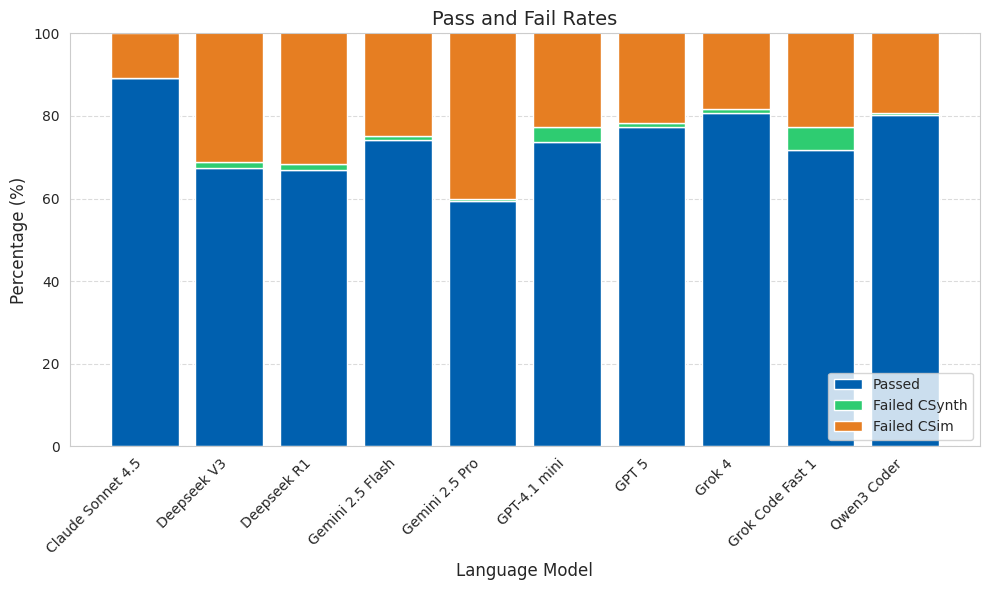

In [ ]:
# Creating the Plots with failure breakdown stacked on top of success
# Filter failure analysis for no_rag only
failure_norag = failure_analysis[failure_analysis['RAG'] == 'no_rag'].copy()

# Get success rate data for no_rag
df_plot_norag = average_success_unsort.reset_index(name='csim_success')
df_plot_norag = df_plot_norag[df_plot_norag['RAG'] == 'no_rag'].copy()

# Rename models for better display
model_names = {
    "gpt-4.1-mini": "GPT-4.1 mini",
    "grok-code-fast-1": "Grok Code Fast 1",
    "gemini-2.5-flash": "Gemini 2.5 Flash",
    "deepseek-chat-v3-0324": "Deepseek V3",
    "deepseek-r1-0528": "Deepseek R1",
    "qwen3-coder": "Qwen3 Coder",
    "grok-4": "Grok 4",
    "gemini-2.5-pro": "Gemini 2.5 Pro",
    "claude-sonnet-4.5": "Claude Sonnet 4.5",
    "gpt-5": "GPT 5"
}

# Merge failure data with success rates
failure_norag['model'] = failure_norag['model'].map(model_names)
df_plot_norag['model'] = df_plot_norag['model'].map(model_names)

# Merge on model name to align data
merged_data = pd.merge(df_plot_norag, failure_norag, on='model', how='left')
merged_data = merged_data.set_index('model')

# --- Visualization ---
plt.figure(figsize=(10, 6))

# Create stacked bar chart: Blue (success) + Green (csynth fail) + Orange (both fail)
x = range(len(merged_data))
success_pct = merged_data['csim_success'].values
csynth_fail_pct = merged_data['csynth_fail_csim_pass_pct'].values
both_fail_pct = merged_data['both_fail_pct'].values

p1 = plt.bar(x, success_pct, label='Passed', color='#0060af')
p2 = plt.bar(x, csynth_fail_pct, bottom=success_pct, label='Failed CSynth', color='#2ecc71')
p3 = plt.bar(x, both_fail_pct, bottom=success_pct + csynth_fail_pct, label='Failed CSim', color='#e67e22')

# Add title and labels
plt.title(f'Pass and Fail Rates', fontsize=14)
plt.ylabel('Percentage (%)', fontsize=12)
plt.xlabel('Language Model', fontsize=12)
plt.ylim(0, 100)
plt.xticks(x, merged_data.index, rotation=45, ha='right')
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig("success_fail_rates.pdf", dpi=300, bbox_inches='tight')   
plt.show()


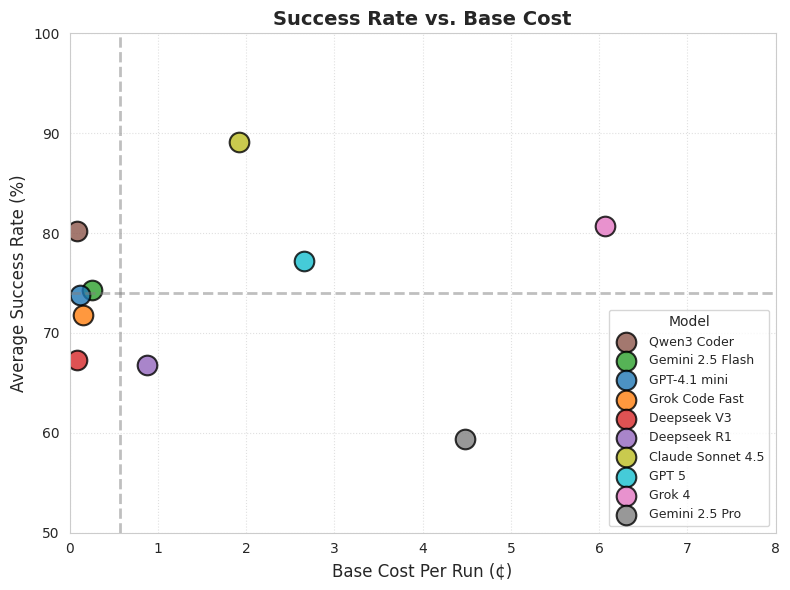

In [ ]:
# Getting the updated cost per success model with model colors

final_plot_df_filtered = plot_df_norag

# Define expensive models
expensive_models = {'claude-sonnet-4.5', 'gemini-2.5-pro', 'gpt-5', 'grok-4'}

# Add a category column
final_plot_df_filtered['category'] = final_plot_df_filtered['model'].apply(
    lambda x: 'Expensive' if x in expensive_models else 'Cheaper'
)


# Define display names
model_names = {
    "gpt-4.1-mini": "GPT-4.1 mini",
    "grok-code-fast-1": "Grok Code Fast",
    "gemini-2.5-flash": "Gemini 2.5 Flash",
    "deepseek-chat-v3-0324": "Deepseek V3",
    "deepseek-r1-0528": "Deepseek R1",
    "qwen3-coder": "Qwen3 Coder",
    "grok-4": "Grok 4",
    "gemini-2.5-pro": "Gemini 2.5 Pro",
    "claude-sonnet-4.5": "Claude Sonnet 4.5",
    "gpt-5": "GPT 5"
}
final_plot_df_filtered['model_display'] = final_plot_df_filtered['model'].map(model_names)

# cheap_df = final_plot_df_filtered[final_plot_df_filtered['category']=='Cheaper']
# expensive_df = final_plot_df_filtered[final_plot_df_filtered['category']=='Expensive']


# Create scatter plot with different color for each model
colors_map = {
    "gpt-4.1-mini": "#1f77b4",
    "grok-code-fast-1": "#ff7f0e",
    "gemini-2.5-flash": "#2ca02c",
    "deepseek-chat-v3-0324": "#d62728",
    "deepseek-r1-0528": "#9467bd",
    "qwen3-coder": "#8c564b",
    "grok-4": "#e377c2",
    "gemini-2.5-pro": "#7f7f7f",
    "claude-sonnet-4.5": "#bcbd22",
    "gpt-5": "#17becf"
}

# Define the model order (same as colors_map order)
model_order = [
    "qwen3-coder",
    "gemini-2.5-flash",
    "gpt-4.1-mini",
    "grok-code-fast-1",
    "deepseek-chat-v3-0324",
    "deepseek-r1-0528",
    "claude-sonnet-4.5",
    "gpt-5",
    "grok-4",
    "gemini-2.5-pro",
]

# Plotting helper
def plot_group(df, title):
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.set_style("whitegrid")

    models_in_order = [m for m in model_order if m in df['model'].values]
    for model in models_in_order:
        model_data = df[df['model'] == model]
        if len(model_data) == 0:
            continue
        ax.scatter(
            model_data['Cost_Per_Run'],
            model_data['Average Success Rate (%)'],
            s=200,
            alpha=0.8,
            color=colors_map.get(model, '#000000'),
            label=model_names.get(model, model),
            edgecolors='black',
            linewidth=1.5
        )
        cost = model_data['Cost_Per_Run'].values
        succ = model_data['Average Success Rate (%)'].values
        cost_std = model_data['Cost_STD'].values


        # ax.errorbar(
        #     cost, succ,
        #     xerr=cost_std,
        #     fmt='o',
        #     color=colors_map.get(model, '#000000'),
        #     ecolor='gray',
        #     elinewidth=2,
        #     capsize=6,
        #     alpha=0.9
        # )

    # Median lines (no legend entries)
    if len(df) > 0:
        median_cost = df['Cost_Per_Run'].median()
        median_success = df['Average Success Rate (%)'].median()
        ax.axhline(median_success, color='gray', linestyle='--', alpha=0.5, linewidth=2)
        ax.axvline(median_cost, color='gray', linestyle='--', alpha=0.5, linewidth=2)

    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xlabel('Base Cost Per Run (¢)', fontsize=12)
    ax.set_ylabel('Average Success Rate (%)', fontsize=12)
    ax.set_xlim(0, 8)
    ax.set_ylim(50, 100)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(title='Model', loc='lower right', fontsize=9, title_fontsize=10, ncol=1)
    plt.tight_layout()
    plt.savefig("success_v_cost.pdf", dpi=300, bbox_inches='tight')   
    plt.show()
    

# Generate two separate figures
plot_group(final_plot_df_filtered, 'Success Rate vs. Base Cost')
# plot_group(expensive_df, 'Expensive Models — Success Rate vs. Base Cost')

